In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
file_path = "../data/cleaned_transactions.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 511566
Columns: 9


C:\Users\USER\AppData\Local\Temp\ipykernel_13700\2758030996.py:3: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [3]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print(df["InvoiceDate"].dtype)

datetime64[us]


In [4]:
daily_sales = (
    df
    .set_index("InvoiceDate")
    .resample("D")["Sales"]
    .sum()
)

print(daily_sales.head())
print("\nNumber of days:", len(daily_sales))

InvoiceDate
2009-12-01    54513.50
2009-12-02    63352.51
2009-12-03    74037.91
2009-12-04    40732.92
2009-12-05     9803.05
Freq: D, Name: Sales, dtype: float64

Number of days: 374


In [5]:
anomaly_df = daily_sales.reset_index()

anomaly_df.columns = ["Date", "Revenue"]

anomaly_df.head()

,Date,Revenue
0,2009-12-01,54513.50
1,2009-12-02,63352.51
2,2009-12-03,74037.91
3,2009-12-04,40732.92
4,2009-12-05,9803.05


In [6]:
X = anomaly_df[["Revenue"]]

print(X.head())
print("\nShape:", X.shape)

    Revenue
0  54513.50
1  63352.51
2  74037.91
3  40732.92
4   9803.05

Shape: (374, 1)


In [7]:
iso_model = IsolationForest(
    contamination=0.05,
    random_state=42
)

iso_model.fit(X)

print("Isolation Forest model trained successfully!")

Isolation Forest model trained successfully!


In [8]:
anomaly_df["Anomaly"] = iso_model.predict(X)

anomaly_df.head(10)

,Date,Revenue,Anomaly
0,2009-12-01,54513.50,1
1,2009-12-02,63352.51,-1
2,2009-12-03,74037.91,-1
3,2009-12-04,40732.92,1
4,2009-12-05,9803.05,1
5,2009-12-06,24613.64,1
6,2009-12-07,45083.35,1
7,2009-12-08,49517.23,1
8,2009-12-09,40616.09,1
9,2009-12-10,44442.11,1


In [9]:
anomaly_df["AnomalyLabel"] = anomaly_df["Anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

anomaly_df.head(10)

,Date,Revenue,Anomaly,AnomalyLabel
0,2009-12-01,54513.50,1,Normal
1,2009-12-02,63352.51,-1,Anomaly
2,2009-12-03,74037.91,-1,Anomaly
3,2009-12-04,40732.92,1,Normal
4,2009-12-05,9803.05,1,Normal
5,2009-12-06,24613.64,1,Normal
6,2009-12-07,45083.35,1,Normal
7,2009-12-08,49517.23,1,Normal
8,2009-12-09,40616.09,1,Normal
9,2009-12-10,44442.11,1,Normal


In [10]:
anomaly_counts = anomaly_df["AnomalyLabel"].value_counts()

print(anomaly_counts)

AnomalyLabel
Normal     355
Anomaly     19
Name: count, dtype: int64


In [11]:
anomalies = anomaly_df[
    anomaly_df["AnomalyLabel"] == "Anomaly"
].copy()

anomalies = anomalies.sort_values(
    "Revenue",
    ascending=False
)

anomalies

,Date,Revenue,Anomaly,AnomalyLabel
300,2010-09-27,118909.670,-1,Anomaly
349,2010-11-15,105185.540,-1,Anomaly
371,2010-12-07,99618.200,-1,Anomaly
342,2010-11-08,90952.911,-1,Anomaly
338,2010-11-04,90056.290,-1,Anomaly
317,2010-10-14,87526.410,-1,Anomaly
308,2010-10-05,84879.590,-1,Anomaly
344,2010-11-10,80244.630,-1,Anomaly
363,2010-11-29,79264.060,-1,Anomaly
2,2009-12-03,74037.910,-1,Anomaly


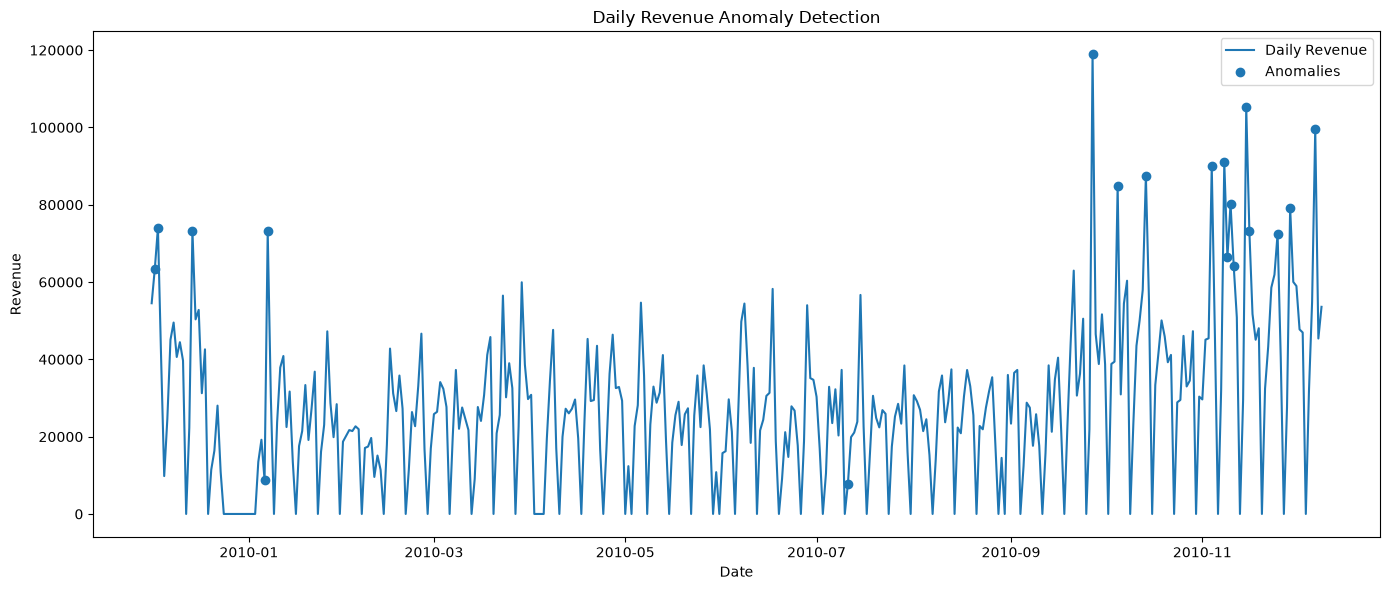

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(
    anomaly_df["Date"],
    anomaly_df["Revenue"],
    label="Daily Revenue"
)

plt.scatter(
    anomalies["Date"],
    anomalies["Revenue"],
    label="Anomalies"
)

plt.title("Daily Revenue Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
print("===== ANOMALY DETECTION SUMMARY =====")

print("Total days:", len(anomaly_df))
print("Normal days:", (anomaly_df["Anomaly"] == 1).sum())
print("Anomaly days:", (anomaly_df["Anomaly"] == -1).sum())

print("\nAnomaly percentage:")
print(
    round(
        (anomaly_df["Anomaly"] == -1).mean() * 100,
        2
    ),
    "%"
)

===== ANOMALY DETECTION SUMMARY =====
Total days: 374
Normal days: 355
Anomaly days: 19

Anomaly percentage:
5.08 %


In [14]:
anomaly_path = "../data/sales_anomalies.csv"

anomaly_df.to_csv(
    anomaly_path,
    index=False
)

print("Anomaly results saved successfully!")
print(anomaly_path)

Anomaly results saved successfully!
../data/sales_anomalies.csv


In [15]:
import joblib

anomaly_model_path = "../data/isolation_forest_model.pkl"

joblib.dump(
    iso_model,
    anomaly_model_path
)

print("Isolation Forest model saved successfully!")

Isolation Forest model saved successfully!


In [16]:
loaded_anomaly_model = joblib.load(
    anomaly_model_path
)

print("Isolation Forest model loaded successfully!")

Isolation Forest model loaded successfully!
